# PIB — Step 3: from entities to bboxes

Given a piece of text found in a page, find the OCR words that carry it and merge their boxes into PIB's
`bbox_2d` format: `[[y_min, x_min, y_max, x_max], ...]`, integers in `[0, 1000]`, one box per text line.

**OCR used:** the frozen Tesseract setting from step 1b (2x bicubic upscale, `--psm 3`, `max(R, G, B)`, no inverted pass).
The notebook loads `pib_ocr_tesseract_v2.zip` if you drop it into the Colab file panel (`/content`); otherwise it
re-runs the OCR with exactly those settings (about 15 minutes).

**Check:** the ground-truth boxes of one page are rebuilt from the ground-truth *texts* only and compared with the
real boxes using `metrics.py` from the PIB repository. The same check is then run on every page of every split.

The functions are saved to `pib_boxes.py` so the next steps can import them:

| Function | What it does |
|---|---|
| `span_to_bbox_2d(page, start, end)` | boxes of a character span of the page text (what GLiNER-style taggers return) |
| `find_text(page, text)` | every place a text occurs in the page (case / whitespace insensitive) |
| `text_to_bbox_2d(page, text)` | boxes of a text found in the page |
| `locate_entities(page, entities)` | places a whole list of `{label, text}` entities (what LLM taggers return) and adds `bbox_2d` |

In [ ]:
# 1. Install + get the PIB repository (for its metrics.py)
!pip -q install datasets
!test -d /content/paint-it-black || git clone -q --depth 1 https://github.com/disi-unibo-nlp/paint-it-black /content/paint-it-black
!git -C /content/paint-it-black log -1 --format="PIB repo commit %h (%ad)" --date=short

PIB repo commit 959b0f1 (2026-11-02)


In [ ]:
# 2. Settings
DATASET   = "disi-unibo-nlp/paint-it-black"
SPLITS    = ["base", "medium", "hard"]
REPO_DIR  = "/content/paint-it-black"
OCR_DIR   = "/content/pib_ocr/tesseract_v2"            # output folder of step 1b
OCR_ZIP   = "/content/pib_ocr_tesseract_v2.zip"        # ... or its zip, dropped into the Colab file panel
OUT_DIR   = "/content/pib_step2"
N_WORKERS = 2

# Frozen OCR settings from step 1b (identical for all splits)
FROZEN = {"upscale": 2.0, "psm": 3, "invert_pass": False, "gray": "max"}

CHECK_PAGE = ("base", 0)       # the page used for the one-page check (split, index)
MAX_ERR    = 0.2               # approximate text search: at most 20% of the characters may differ

In [ ]:
# 3. Load the dataset
from datasets import load_dataset

try:
    dsd = load_dataset(DATASET)
except Exception as exc:
    # Private or gated repo: add your token as a Colab secret named HF_TOKEN (key icon on the left) and re-run.
    print(f"Anonymous load failed ({type(exc).__name__}); retrying with HF_TOKEN from Colab secrets...")
    from google.colab import userdata
    from huggingface_hub import login
    login(token=userdata.get("HF_TOKEN"))
    dsd = load_dataset(DATASET)

for s in SPLITS:
    print(f"{s:7s} {len(dsd[s]):4d} pages")

README.md:   0%|          | 0.00/16.8k [00:00<?, ?B/s]

data/base-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 78.1MB            

data/base-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/medium-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  302MB            

data/medium-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/medium-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  305MB            

... (3 outputs left out)

Generating base split:   0%|          | 0/138 [00:00<?, ? examples/s]

Generating medium split:   0%|          | 0/138 [00:00<?, ? examples/s]

Generating hard split:   0%|          | 0/138 [00:00<?, ? examples/s]

base     138 pages
medium   138 pages
hard     138 pages


In [ ]:
# 4. OCR output through building it with the frozen settings
import json, shutil
from pathlib import Path


def read_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def _ocr_complete(folder):
    return all((Path(folder) / f"{s}.jsonl").exists() and len(read_jsonl(Path(folder) / f"{s}.jsonl")) == len(dsd[s])
               for s in SPLITS)


if not _ocr_complete(OCR_DIR) and Path(OCR_ZIP).exists():
    shutil.unpack_archive(OCR_ZIP, OCR_DIR)
    print("Unzipped", OCR_ZIP)

if _ocr_complete(OCR_DIR):
    meta_path = Path(OCR_DIR) / "meta.json"
    ocr_meta = json.loads(meta_path.read_text()) if meta_path.exists() else {}
    if ocr_meta.get("settings") != FROZEN:
        raise RuntimeError(f"{OCR_DIR} was not produced with the frozen settings {FROZEN} "
                           f"(found {ocr_meta.get('settings')}). Remove it to rebuild the OCR here.")
    print("Using the step 1b OCR files in", OCR_DIR)
else:
    print("OCR files not found -> running Tesseract with the frozen settings (about 15 minutes)")
    get_ipython().system("apt-get -qq install -y tesseract-ocr > /dev/null && pip -q install pytesseract")

    import os
    os.environ["OMP_THREAD_LIMIT"] = "1"   # one thread per Tesseract process; we parallelise over pages instead

    import json, time, statistics
    from pathlib import Path
    from concurrent.futures import ThreadPoolExecutor

    import pytesseract
    from pytesseract import Output
    from PIL import Image, ImageChops, ImageOps


    def to_gray(img, mode):
        """RGB page -> single-channel image given to Tesseract."""
        img = img.convert("RGB")
        if mode == "luma":                      # standard grayscale conversion
            return img.convert("L")
        if mode == "blue":                      # blue channel: blue ink turns light, black text stays black
            return img.getchannel("B")
        if mode == "max":                       # max(R, G, B): any saturated colour turns light
            r, g, b = img.split()
            return ImageChops.lighter(ImageChops.lighter(r, g), b)
        raise ValueError(f"unknown gray mode: {mode}")


    def tesseract_words(gray, psm, lang="eng"):
        """One Tesseract pass. Returns word dicts with boxes normalised by the size of `gray`."""
        W, H = gray.size
        # Output.DICT keeps every token as a string (a DataFrame would turn words like "NA" into NaN).
        d = pytesseract.image_to_data(gray, lang=lang, config=f"--oem 1 --psm {psm}", output_type=Output.DICT)
        words = []
        for k in range(len(d["text"])):
            tok = (d["text"][k] or "").strip()
            if d["level"][k] != 5 or not tok:   # 5 = word level
                continue
            left, top, w, h = d["left"][k], d["top"][k], d["width"][k], d["height"][k]
            clip = lambda v: round(min(1.0, max(0.0, v)), 5)
            words.append({"text": tok, "conf": float(d["conf"][k]),
                          "bbox": [clip(top / H), clip(left / W), clip((top + h) / H), clip((left + w) / W)]})
        return words


    def _boxes_overlap(a, b):
        """True if two [y0, x0, y1, x1] boxes share any area."""
        return min(a[2], b[2]) > max(a[0], b[0]) and min(a[3], b[3]) > max(a[1], b[1])


    def build_lines(words):
        """Group words into visual lines and order them top-to-bottom, left-to-right.

        Words are visited left to right. A word joins the nearest line whose last "real" word
        (one containing a letter or digit) it overlaps vertically by at least half of the smaller height;
        following the line word by word tolerates a slight skew. Two real words must also have similar heights (ratio <= 3),
        so an oversized noise box cannot glue several lines together. Punctuation-only tokens join by
        overlap alone and are never used as the reference for the next word.
        """
        height = lambda w: max(1e-9, w["bbox"][2] - w["bbox"][0])
        real = lambda w: any(ch.isalnum() for ch in w["text"])
        lines = []                                             # each: {"words": [...], "ref": word}
        for w in sorted(words, key=lambda w: (w["bbox"][1], w["bbox"][0])):
            best, best_key = None, None
            for ln in lines:
                ref = ln["ref"]
                ov = (min(w["bbox"][2], ref["bbox"][2]) - max(w["bbox"][0], ref["bbox"][0])) / min(height(w), height(ref))
                similar = max(height(w), height(ref)) <= 3 * min(height(w), height(ref))
                if ov >= 0.5 and (similar or not real(w) or not real(ref)):
                    key = (abs(w["bbox"][1] - ref["bbox"][3]), -ov)  # nearest line end, then best overlap
                    if best is None or key < best_key:
                        best, best_key = ln, key
            if best is None:
                lines.append({"words": [w], "ref": w})
            else:
                best["words"].append(w)
                if real(w) or not real(best["ref"]):
                    best["ref"] = w
        y_mid = lambda ln: statistics.median((w["bbox"][0] + w["bbox"][2]) / 2 for w in ln["words"])
        lines.sort(key=lambda ln: (y_mid(ln), ln["words"][0]["bbox"][1]))
        return [ln["words"] for ln in lines]


    def ocr_page(img, cfg):
        """OCR one PIL page with the settings in `cfg`.

        Returns (text, words, (width, height)). Words are in reading order; each has its text,
        a [y_min, x_min, y_max, x_max] box in [0, 1], [start, end) offsets into `text`,
        its line index and the pass that produced it (1 = normal, 2 = inverted image).
        """
        orig_size = img.size
        gray = to_gray(img, cfg["gray"])
        if cfg["upscale"] != 1.0:
            gray = gray.resize((round(gray.width * cfg["upscale"]), round(gray.height * cfg["upscale"])), Image.BICUBIC)
        # Boxes are divided by the size of the image Tesseract saw, so they are already
        # in [0, 1] of the original page whatever the upscale factor.
        words = tesseract_words(gray, cfg["psm"])
        for w in words:
            w["pass"] = 1
        if cfg["invert_pass"]:
            first = list(words)
            for w in tesseract_words(ImageOps.invert(gray), cfg["psm"]):
                if not any(_boxes_overlap(w["bbox"], f["bbox"]) for f in first):
                    w["pass"] = 2
                    words.append(w)

        out, parts, pos = [], [], 0
        for li, line in enumerate(build_lines(words)):
            for wi, w in enumerate(line):
                sep = "" if not out else (" " if wi else "\n")
                parts.append(sep + w["text"])
                pos += len(sep)
                out.append({"i": len(out), "text": w["text"], "bbox": w["bbox"], "start": pos,
                            "end": pos + len(w["text"]), "conf": w["conf"], "line": li, "pass": w["pass"]})
                pos += len(w["text"])
        return "".join(parts), out, orig_size

    Path(OCR_DIR).mkdir(parents=True, exist_ok=True)
    for s in SPLITS:
        out_path, ds = Path(OCR_DIR) / f"{s}.jsonl", dsd[s]
        n_done = len(read_jsonl(out_path)) if out_path.exists() else 0      # resume if interrupted

        def one(i):
            row = ds[i]
            text, words, (width, height) = ocr_page(row["image"], FROZEN)
            return {"split": s, "idx": i, "source_pdf": row.get("source_pdf"), "page": row.get("page"),
                    "total_pages": row.get("total_pages"), "doc_type": row.get("doc_type"),
                    "width": width, "height": height, "text": text, "words": words}

        with ThreadPoolExecutor(max_workers=N_WORKERS) as pool, open(out_path, "a", encoding="utf-8") as f:
            for start in range(n_done, len(ds), 8):
                for rec in pool.map(one, range(start, min(start + 8, len(ds)))):
                    f.write(json.dumps(rec, ensure_ascii=False) + "\n")
                f.flush()
                print(f"\r[{s}] {min(start + 8, len(ds))}/{len(ds)} pages", end="")
        print()
    ocr_meta = {"engine": "tesseract", "tesseract_version": str(pytesseract.get_tesseract_version()),
                "settings": FROZEN, "note": "rebuilt in the step 2 notebook with the step 1b code"}
    (Path(OCR_DIR) / "meta.json").write_text(json.dumps(ocr_meta, indent=2))

ocr = {s: read_jsonl(Path(OCR_DIR) / f"{s}.jsonl") for s in SPLITS}
for s in SPLITS:
    assert [p["idx"] for p in ocr[s]] == list(range(len(dsd[s]))), f"{s}: OCR pages do not match the dataset"
    print(f"{s:7s} {len(ocr[s]):4d} pages, {sum(len(p['words']) for p in ocr[s]):6d} words")

OCR files not found -> running Tesseract with the frozen settings (about 15 minutes)
[base] 138/138 pages
[medium] 138/138 pages
[hard] 138/138 pages
base     138 pages,  48406 words
medium   138 pages,  45723 words
hard     138 pages,  45311 words


In [ ]:
%%writefile /content/pib_boxes.py
"""PIB: from entity text to `bbox_2d` boxes, using the word boxes saved by the OCR step."""
import re
from itertools import combinations

import numpy as np


def span_to_bbox_2d(page, start, end, pad=None, scale=1000):
    """Boxes of the page-text span [start, end) in PIB's `bbox_2d` format.

    Takes the OCR words that overlap the span, groups them by visual line and returns one
    enclosing box per line: [[y_min, x_min, y_max, x_max], ...] as integers in [0, scale].
    If the span covers only part of a word (e.g. "STERLING" inside "STERLING,"), the word box
    is cut horizontally in proportion to the characters covered.
    `pad` = (top, left, bottom, right), each a fraction of the line-box height, enlarges every
    line box by a fixed amount (OCR boxes hug the glyphs; annotation boxes leave a margin).
    """
    per_line = {}
    for w in page["words"]:
        if w["start"] >= end or w["end"] <= start:
            continue
        y0, x0, y1, x1 = w["bbox"]
        n = w["end"] - w["start"]
        a = (max(start, w["start"]) - w["start"]) / n          # covered share of the word, left edge
        b = (min(end, w["end"]) - w["start"]) / n              # ... right edge
        xa, xb = x0 + a * (x1 - x0), x0 + b * (x1 - x0)
        box = per_line.setdefault(w["line"], [y0, xa, y1, xb])
        box[0], box[1], box[2], box[3] = min(box[0], y0), min(box[1], xa), max(box[2], y1), max(box[3], xb)

    out = []
    for line in sorted(per_line):
        y0, x0, y1, x1 = per_line[line]
        if pad:
            h = y1 - y0                                         # line-box height (fraction of page height)
            hx = h * page["height"] / page["width"]             # the same length as a fraction of page width
            y0, x0, y1, x1 = y0 - pad[0] * h, x0 - pad[1] * hx, y1 + pad[2] * h, x1 + pad[3] * hx
        out.append([int(round(min(1.0, max(0.0, v)) * scale)) for v in (y0, x0, y1, x1)])
    return out


_CHAR_MAP = {}
for _chars, _rep in (("\u2018\u2019\u201a\u201b\u2032\u02bc\u00b4`", "'"), ("\u201c\u201d\u201e\u201f\u2033", '"'),
                     ("\u2010\u2011\u2012\u2013\u2014\u2015\u2212\u00ad", "-"),
                     ("\u00a0\u2007\u202f\u2000\u2001\u2002\u2003\u2004\u2005\u2006\u2008\u2009\u200a\u3000"
                      "\u200b\u200c\u200d\u2060\ufeff\u200e\u200f", " ")):
    for _ch in _chars:
        _CHAR_MAP[ord(_ch)] = _rep


def norm_chars(text):
    """Curly quotes, dashes and invisible spaces mapped to ASCII; same length as the input."""
    return text.translate(_CHAR_MAP)


def _squash(text):
    """Lower-case `text` without whitespace and without stand-alone punctuation tokens
    (e.g. the "," in "Vincent's , Specialized"), plus the original index of every kept character.
    Quotes, dashes and invisible spaces are normalised first."""
    text = norm_chars(text)
    chars, index = [], []
    for m in re.finditer(r"\S+", text):
        tok = m.group()
        if not any(ch.isalnum() for ch in tok):
            continue
        for k, ch in enumerate(tok):
            chars.append(ch.lower())
            index.append(m.start() + k)
    return "".join(chars), index


def _edit_row(pattern, text_codes, anchored=False):
    """Edit distance between `pattern` and the text ending at each position.

    anchored=False: the match may start anywhere in the text (best substring ending there).
    anchored=True:  the match must start at the beginning of the text.
    """
    n = len(text_codes)
    idx = np.arange(n + 1)
    prev = idx.copy() if anchored else np.zeros(n + 1, dtype=np.int64)
    for i, ch in enumerate(pattern, start=1):
        cand = np.empty(n + 1, dtype=np.int64)
        cand[0] = i
        cand[1:] = np.minimum(prev[:-1] + (text_codes != ord(ch)), prev[1:] + 1)
        prev = np.minimum.accumulate(cand - idx) + idx         # allows skipping text characters
    return prev


def find_text(page, text, max_err=0.0):
    """All places where `text` occurs in the OCR text of the page, in reading order.

    Matching ignores case and whitespace, so it also works across line breaks.
    Returns a list of (start, end, n_errors) with character offsets into page["text"].
    If nothing matches exactly and max_err > 0, the closest approximate matches are returned,
    provided they need at most max_err * len(text) character edits (OCR misreadings).
    """
    cache = page.get("_squashed")
    if cache is None:
        cache = page["_squashed"] = _squash(page["text"])
    hay, index = cache
    needle, _ = _squash(text)
    if not needle or not hay:
        return []

    spans, pos = [], hay.find(needle)
    while pos != -1:
        spans.append((index[pos], index[pos + len(needle) - 1] + 1, 0))
        pos = hay.find(needle, pos + len(needle))
    limit = int(max_err * len(needle))
    if spans or limit == 0:
        return spans

    codes = np.frombuffer(hay.encode("utf-32-le"), dtype=np.uint32)
    last = _edit_row(needle, codes)
    best = int(last.min())
    if best > limit:
        return []
    candidates = []
    for end_pos in np.flatnonzero(last == best):
        end_pos = int(end_pos)
        if end_pos == 0:
            continue
        window = codes[max(0, end_pos - len(needle) - limit):end_pos]
        back = _edit_row(needle[::-1], window[::-1], anchored=True)            # backwards from the end
        lengths = np.flatnonzero(back == best)                  # match lengths reaching the same distance
        length = int(lengths[np.argmin(np.abs(lengths - len(needle)))])
        if length > 0:
            candidates.append((abs(length - len(needle)), end_pos - length, end_pos))
    chosen = []                                                 # prefer matches as long as the query
    for _, start_pos, end_pos in sorted(candidates):
        if all(end_pos <= s or start_pos >= e for s, e in chosen):
            chosen.append((start_pos, end_pos))
    return [(index[s], index[e - 1] + 1, best) for s, e in sorted(chosen)]


def _column_runs(page):
    """Per OCR line, the runs of words separated by wide horizontal gaps (one run = one column / cell)."""
    cache = page.get("_runs")
    if cache is not None:
        return cache
    lines = {}
    for w in page["words"]:
        lines.setdefault(w["line"], []).append(w)
    runs = {}
    for line, ws in lines.items():
        ws = sorted(ws, key=lambda w: w["bbox"][1])
        h = sorted(w["bbox"][2] - w["bbox"][0] for w in ws)[len(ws) // 2] * page.get("height", 1) / page.get("width", 1)
        cur = [ws[0]]
        runs[line] = []
        for w in ws[1:]:
            if w["bbox"][1] - cur[-1]["bbox"][3] > 2.0 * h:          # gap wider than ~2 letter heights: new column
                runs[line].append(cur)
                cur = [w]
            else:
                cur.append(w)
        runs[line].append(cur)
    page["_runs"] = runs
    return runs


def _piece_geometry(page, start, end):
    """Line, box and column run of a span that lies on one OCR line (None if it spans several lines)."""
    ws = [w for w in page["words"] if w["start"] < end and w["end"] > start]
    if not ws or len({w["line"] for w in ws}) != 1:
        return None
    line = ws[0]["line"]
    run = next((r for r in _column_runs(page)[line] if any(w is r_w or w["i"] == r_w["i"] for r_w in r for w in ws)), ws)
    ids = {w["i"] for w in ws}
    x1 = max(w["bbox"][3] for w in ws)
    after = [w["bbox"][1] for r in _column_runs(page)[line] for w in r if w["bbox"][1] >= x1 - 1e-6 and w["i"] not in ids]
    return {"line": line, "y0": min(w["bbox"][0] for w in ws), "x0": min(w["bbox"][1] for w in ws),
            "y1": max(w["bbox"][2] for w in ws), "x1": x1,
            "run_x0": run[0]["bbox"][1], "run_x1": run[-1]["bbox"][3],
            "starts_run": run[0]["i"] in ids, "ends_run": run[-1]["i"] in ids,
            "next_x0": min(after) if after else None,            # where the next word on the same line starts
            "next_run_x0": next((r[0]["bbox"][1] for r in _column_runs(page)[line] if r[0]["bbox"][1] > run[-1]["bbox"][3]), None)}


def _line_between(page, prev, nxt):
    """True if some OCR word lies vertically between the two pieces and horizontally inside their column."""
    x0, x1 = min(prev["run_x0"], nxt["x0"]), max(prev["x1"], nxt["x1"])
    for w in page["words"]:
        cy = (w["bbox"][0] + w["bbox"][2]) / 2
        if prev["y1"] < cy < nxt["y0"] and w["bbox"][3] > x0 and w["bbox"][1] < x1 and any(c.isalnum() for c in w["text"]):
            return True
    return False


def _column_start(page, x, lines, tol=0.005):
    """True if at least two of the given lines have a word starting at x (a left-aligned table column)."""
    n = 0
    for line in lines:
        if any(abs(w["bbox"][1] - x) <= tol for r in _column_runs(page).get(line, []) for w in r):
            n += 1
    return n >= 2


def _continues(prev, nxt, page=None, x_tol=0.03):
    """True if `nxt` continues `prev` on the next line of the same column: just below, `nxt` starts its
    column run, and it starts between the left edge of prev's column and the end of prev. `prev` must end
    its cell, which is recognised in two ways:
    - nothing follows it closely on its line (wide gap or end of line), e.g. "Phone: (206)" / "555-8812";
    - in a tight table, the next word on its line (e.g. "Phone:") starts after the end of nxt's text and is a
      column start: the next line continues after a gap at that column, or the word is left-aligned with
      words on other rows ("1422 Rue de la Montagne, Apt 4B, | Phone:" / "Montreal, QC H3G 1Z3").
    This covers wrapped titles, addresses and field values."""
    h = prev["y1"] - prev["y0"]
    below = (nxt["line"] != prev["line"] and nxt["y0"] > prev["y0"] + 0.5 * h and nxt["y0"] - prev["y1"] < 1.5 * h)
    if not (below and nxt["starts_run"] and prev["run_x0"] - x_tol <= nxt["x0"] <= prev["x1"]):
        return False
    if prev["ends_run"]:
        return True
    nx = prev["next_x0"]
    if nx is None or nxt["run_x1"] >= nx:
        return False
    if nxt["next_run_x0"] is not None and nxt["next_run_x0"] >= nx - x_tol:
        return True
    if page is not None:
        nearby = [l for l in range(prev["line"] - 3, nxt["line"] + 4) if l not in (prev["line"], nxt["line"])]
        return _column_start(page, nx, nearby)
    return False


def find_text_lines(page, text, max_err=0.0, max_lines=3):
    """Find a text that wraps over 2-3 lines of one column, while other text (e.g. a second column)
    sits between its pieces in the page text. Returns a list of matches, each (pieces, n_errors) with
    pieces = [(start, end), ...], one per line, best match first.
    """
    tokens = norm_chars(text).split()
    best = []
    for n_lines in range(2, min(max_lines, len(tokens)) + 1):
        for cuts in combinations(range(1, len(tokens)), n_lines - 1):
            parts = [" ".join(tokens[a:b]) for a, b in zip((0,) + cuts, cuts + (len(tokens),))]
            if any(not _squash(p)[0] for p in parts):
                continue
            chains = [([], 0, None)]                           # (pieces, errors, geometry of last piece)
            for part in parts:
                new = []
                for s0, e0, err in find_text(page, part, max_err):
                    geo = _piece_geometry(page, s0, e0)
                    if geo is None:
                        continue
                    for pieces, errs, last in chains:
                        if last is None or (_continues(last, geo, page) and not _line_between(page, last, geo)):
                            new.append((pieces + [(s0, e0)], errs + err, geo))
                chains = new
                if not chains:
                    break
            best += [(pieces, errs) for pieces, errs, _ in chains]
    best.sort(key=lambda m: (m[1], m[0][0][0]))
    return best


def text_to_bbox_2d(page, text, occurrence=0, max_err=0.0, pad=None):
    """`bbox_2d` of the given occurrence of `text` in the page ([] if the text is not found).
    Falls back to a multi-line search when the text is not contiguous in the page text."""
    spans = find_text(page, text, max_err)
    if occurrence < len(spans):
        return span_to_bbox_2d(page, spans[occurrence][0], spans[occurrence][1], pad)
    multi = find_text_lines(page, text, max_err)
    k = occurrence - len(spans)
    if k < len(multi):
        return [b for s0, e0 in multi[k][0] for b in span_to_bbox_2d(page, s0, e0, pad)]
    return []


def locate_entities(page, entities, max_err=0.0, pad=None):
    """Give every {"label", "text"} entity its own place on the page and its `bbox_2d`.

    Longer texts are placed first and no two entities may share characters, so a short text
    ("STERLING") cannot land inside a longer entity ("MARCUS J STERLING"). Entities with the
    same text take the free occurrences in the order they appear in `entities`. A text that is
    not contiguous in the page text is searched line by line in the same column (multi-line).
    Returns new dicts: {"label", "text", "bbox_2d", "span", "pieces", "n_errors"}; an entity that
    cannot be placed gets bbox_2d = [] and span = None.
    """
    out = [dict(label=e["label"], text=e["text"], bbox_2d=[], span=None, pieces=None, n_errors=None) for e in entities]
    used = []                                                   # character ranges already taken
    free = lambda pieces: all(all(e <= s or b >= t for s, t in used) for b, e in pieces)
    order = sorted(range(len(out)), key=lambda i: (-len(_squash(out[i]["text"])[0]), i))
    for i in order:
        candidates = [([(a, b)], err) for a, b, err in find_text(page, out[i]["text"], max_err)]
        if not any(free(p) for p, _ in candidates):
            candidates += find_text_lines(page, out[i]["text"], max_err)
        for pieces, err in candidates:
            if free(pieces):
                used.extend(pieces)
                out[i].update(bbox_2d=[b for a, c in pieces for b in span_to_bbox_2d(page, a, c, pad)],
                              span=[pieces[0][0], pieces[-1][1]], pieces=[list(p) for p in pieces], n_errors=err)
                break
    return out

Writing /content/pib_boxes.py


In [ ]:
# 6. Import the box functions and the PIB metrics
import sys, importlib
sys.path.insert(0, "/content")
sys.path.insert(0, f"{REPO_DIR}/src")

import pib_boxes
importlib.reload(pib_boxes)
from pib_boxes import span_to_bbox_2d, find_text, text_to_bbox_2d, locate_entities
from inference.metrics import compute_metrics, bbox_iou          # PIB repository, unchanged

IOU_THRESHOLDS = [0.25, 0.5, 0.75]


def as_records(anns):
    """Annotations as a list of dicts (handles both list-of-dicts and dict-of-lists layouts)."""
    if isinstance(anns, dict):
        keys = list(anns)
        return [dict(zip(keys, vals)) for vals in zip(*(anns[k] for k in keys))]
    return anns or []


def gt_entities(row):
    """Ground truth of one page in reading order: {"label", "text", "bboxes"} with boxes in [0, 1]."""
    ents = [{"label": a["label"], "text": a["text"], "bboxes": [list(b) for b in a["bboxes"]]}
            for a in as_records(row["annotations"])]
    return sorted(ents, key=lambda e: (e["bboxes"][0][0], e["bboxes"][0][1]) if e["bboxes"] else (9, 9))


def to_metric_format(entities):
    """PIB predictions ({label, text, bbox_2d in 0-1000}) -> what metrics.py scores (boxes in 0-1).
    Same rescaling as `_rescale_entities` in the repo's run_inference.py."""
    return [{"label": e["label"], "text": e["text"], "bbox_2d": [[c / 1000.0 for c in b] for b in e["bbox_2d"]]}
            for e in entities]


def rebuild_page(split, idx, gts, max_err=0.0, pad=None):
    """Rebuild the boxes of one page from the ground-truth labels and texts only."""
    return locate_entities(ocr[split][idx], [{"label": g["label"], "text": g["text"]} for g in gts], max_err, pad)


def summarise(m):
    """The paper's headline numbers from the dict returned by compute_metrics."""
    e2e = m["bbox_localization"]["end_to_end"]
    return {"spatial_f1": sum(e2e[f"@{t}"]["macro_f1"] for t in IOU_THRESHOLDS) / len(IOU_THRESHOLDS),
            **{f"f1@{t}": e2e[f"@{t}"]["micro"]["f1"] for t in IOU_THRESHOLDS},
            "mean_iou": m["summary"]["unconditional_mean_iou"], "pass_rate": m["summary"]["pass_rate"]}


gt = {s: [gt_entities(r) for r in dsd[s].select_columns(["annotations"])] for s in SPLITS}   # no image decoding
print({s: sum(len(g) for g in gt[s]) for s in SPLITS}, "ground-truth entities")

{'base': 2579, 'medium': 2579, 'hard': 2579} ground-truth entities


base / page 0: 16 ground-truth entities, 15 found in the OCR text
label                      text                                     IoU   rebuilt bbox_2d  |  real boxes (x1000)
NAME:FACILITY              CENTRAL VALLEY CARDIOLOGY INSTITUTE     0.00   NOT FOUND  |  [[59, 95, 74, 690]]
ADDRESS:FACILITY           1422 MEDICAL PLAZA WAY, SACRAMENTO, CA  0.89   [[79, 97, 88, 485]]  |  [[79, 96, 89, 488]]
CONTACT:FACILITY           (916) 555-0192                          0.76   [[92, 134, 100, 240]]  |  [[91, 133, 101, 242]]
CONTACT:FACILITY           (916) 555-0193                          0.70   [[92, 293, 100, 399]]  |  [[91, 292, 102, 402]]
NAME:PATIENT               MARCUS J STERLING                       0.76   [[136, 218, 147, 403]]  |  [[135, 217, 149, 405]]
DATE_OF_BIRTH:UNDER_89     05/18/1982                              0.87   [[152, 121, 162, 213]]  |  [[151, 121, 162, 216]]
ID:PATIENT_ID              CV-9921-084                             0.73   [[185, 182, 194, 288]]  |  [[

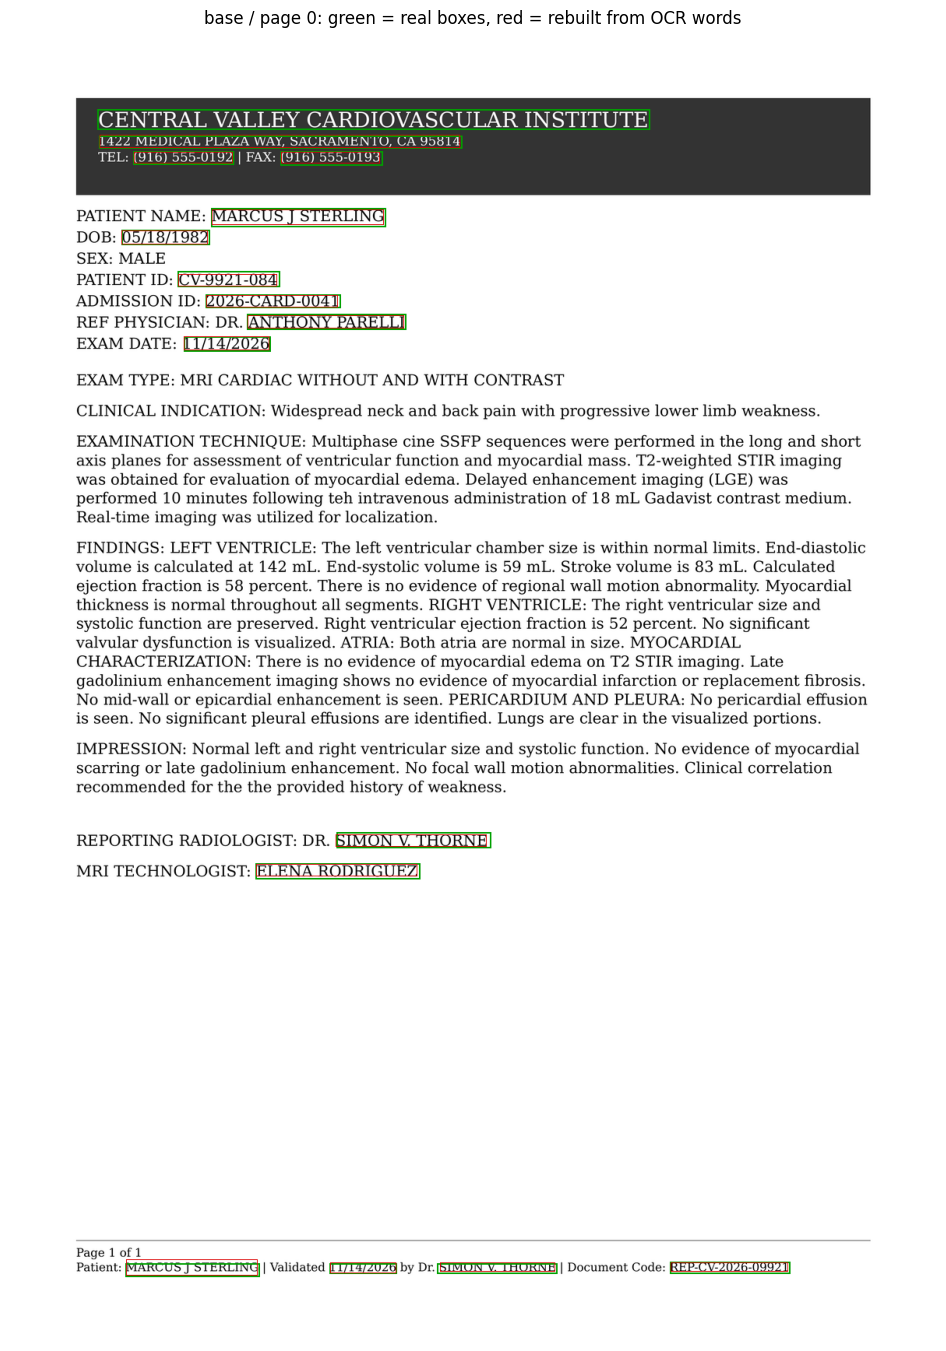

In [ ]:
# 7. CHECK (one page): rebuild the ground-truth boxes from the texts and compare with the real ones
import matplotlib.pyplot as plt
from PIL import ImageDraw


def check_one_page(split, idx, pad=None, show=True):
    gts = gt[split][idx]
    preds = rebuild_page(split, idx, gts, pad=pad)
    scored = to_metric_format(preds)

    print(f"{split} / page {idx}: {len(gts)} ground-truth entities, {sum(p['span'] is not None for p in preds)} found in the OCR text")
    print(f"{'label':26s} {'text':38s} {'IoU':>5s}   rebuilt bbox_2d  |  real boxes (x1000)")
    for g, p, sc in zip(gts, preds, scored):
        iou = bbox_iou(sc["bbox_2d"], g["bboxes"])
        real = [[round(c * 1000) for c in b] for b in g["bboxes"]]
        print(f"{g['label']:26s} {g['text'][:38]:38s} {iou:5.2f}   {p['bbox_2d'] if p['bbox_2d'] else 'NOT FOUND'}  |  {real}")

    m = compute_metrics([scored], [gts], iou_thresholds=IOU_THRESHOLDS)
    e2e = m["bbox_localization"]["end_to_end"]
    print("\nmetrics.py on this page (texts and labels are the ground truth, so only the boxes are tested):")
    print("  F1 at IoU 0.25 / 0.5 / 0.75 : " + " / ".join(f"{e2e[f'@{t}']['micro']['f1']:.1%}" for t in IOU_THRESHOLDS))
    print(f"  mean IoU of matched boxes   : {m['summary']['mean_iou']:.3f}")
    print(f"  Pass Rate                   : {m['summary']['pass_rate']:.1%}")

    if show:
        img = dsd[split][idx]["image"].convert("RGB").copy()
        W, H = img.size
        draw = ImageDraw.Draw(img)
        for g in gts:
            for y0, x0, y1, x1 in g["bboxes"]:
                draw.rectangle([x0 * W, y0 * H, x1 * W, y1 * H], outline=(0, 160, 0), width=2)
        for p in scored:
            for y0, x0, y1, x1 in p["bbox_2d"]:
                draw.rectangle([x0 * W, y0 * H, x1 * W, y1 * H], outline=(220, 0, 0), width=1)
        Path(OUT_DIR).mkdir(parents=True, exist_ok=True)
        img.save(Path(OUT_DIR) / f"check_{split}_{idx:04d}{'_padded' if pad else ''}.png")
        plt.figure(figsize=(12, 17)); plt.imshow(img); plt.axis("off")
        plt.title(f"{split} / page {idx}: green = real boxes, red = rebuilt from OCR words" + (" (padded)" if pad else ""))
        plt.show()
    return m


m_page = check_one_page(*CHECK_PAGE)

Measured on 117 entities of base pages [11, 22, 46, 59, 83, 93, 115, 126]
Real box minus OCR box, as a fraction of the OCR box height (median):
  top +0.06   left +0.08   bottom +0.13   right +0.24
PAD = [0.06, 0.08, 0.13, 0.24]  (top, left, bottom, right)

base / page 0: 16 ground-truth entities, 15 found in the OCR text
label                      text                                     IoU   rebuilt bbox_2d  |  real boxes (x1000)
NAME:FACILITY              CENTRAL VALLEY CARDIOLOGY INSTITUTE     0.00   NOT FOUND  |  [[59, 95, 74, 690]]
ADDRESS:FACILITY           1422 MEDICAL PLAZA WAY, SACRAMENTO, CA  0.95   [[79, 96, 89, 488]]  |  [[79, 96, 89, 488]]
CONTACT:FACILITY           (916) 555-0192                          0.94   [[91, 133, 101, 242]]  |  [[91, 133, 101, 242]]
CONTACT:FACILITY           (916) 555-0193                          0.88   [[91, 292, 101, 402]]  |  [[91, 292, 102, 402]]
NAME:PATIENT               MARCUS J STERLING                       0.91   [[135, 217, 148, 40

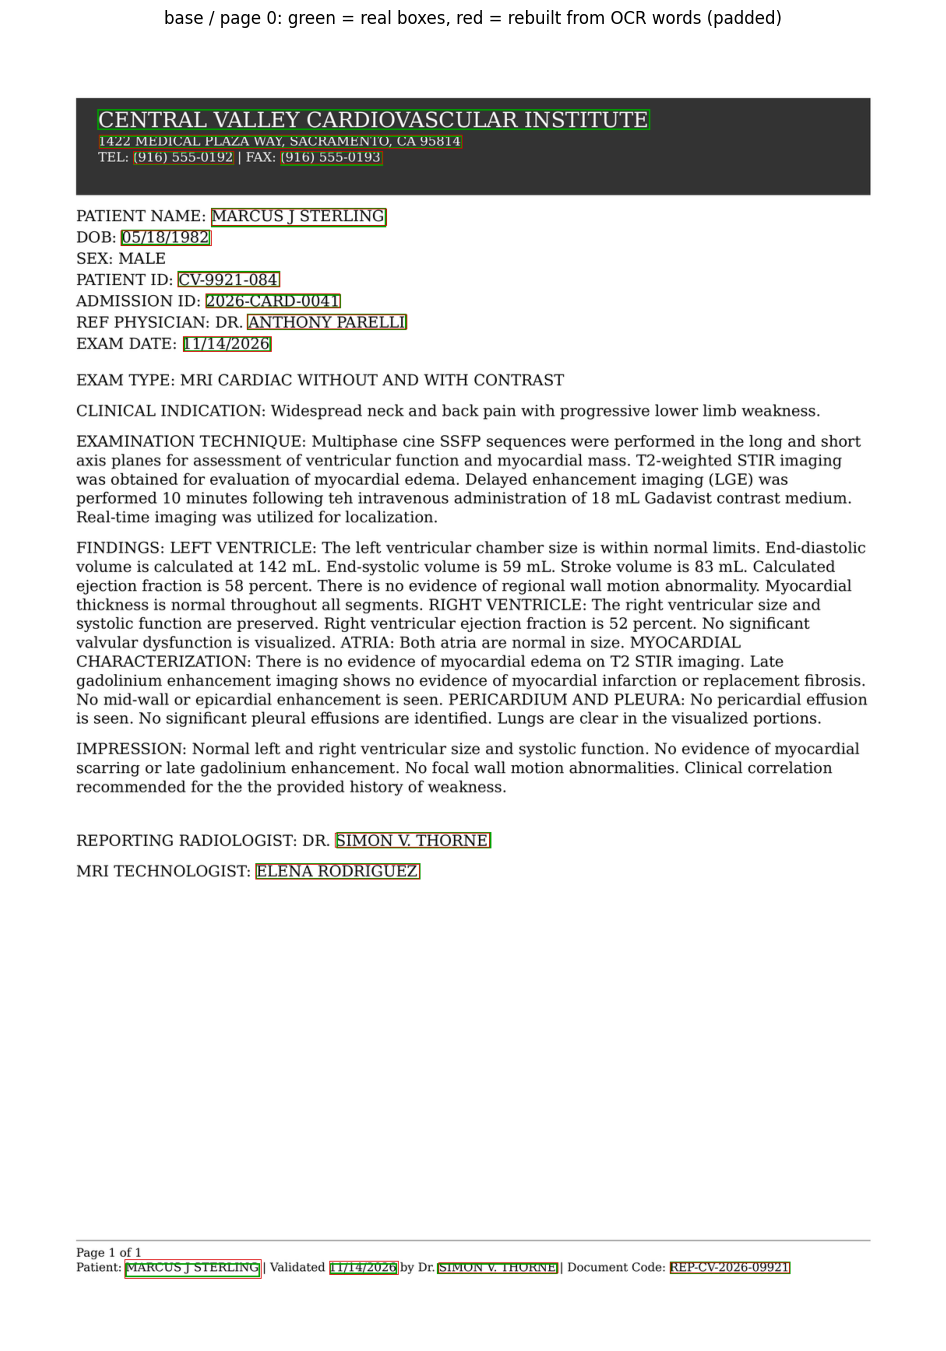

In [ ]:
# 8. Box margin: OCR boxes hug the glyphs, annotation boxes may leave a margin around the text.
#    Measure the difference on the (base only), then freeze it as PAD.
import statistics

TUNE_PAGES = (ocr_meta.get("tuning") or {}).get("pages")
if not TUNE_PAGES:                                   # same rule as step 1b: 2 pages per document type
    doc_types = list(dsd["base"]["doc_type"])
    TUNE_PAGES = sorted({[i for i, d in enumerate(doc_types) if d == dt][(k + 1) * doc_types.count(dt) // 3]
                         for dt in set(doc_types) for k in range(2)})

offsets = []                                         # (top, left, bottom, right) in units of the box height
for idx in TUNE_PAGES:
    page, gts = ocr["base"][idx], gt["base"][idx]
    for g, p in zip(gts, rebuild_page("base", idx, gts)):
        if p["n_errors"] != 0 or len(p["bbox_2d"]) != 1 or len(g["bboxes"]) != 1:
            continue                                  # only exact, single-line entities
        py0, px0, py1, px1 = (c / 1000 for c in p["bbox_2d"][0])
        gy0, gx0, gy1, gx1 = g["bboxes"][0]
        h = py1 - py0
        if h <= 0:
            continue
        hx = h * page["height"] / page["width"]
        offsets.append(((py0 - gy0) / h, (px0 - gx0) / hx, (gy1 - py1) / h, (gx1 - px1) / hx))

PAD = [round(statistics.median(o[k] for o in offsets), 2) for k in range(4)]
print(f"Measured on {len(offsets)} entities of base pages {TUNE_PAGES}")
print("Real box minus OCR box, as a fraction of the OCR box height (median):")
print(f"  top {PAD[0]:+.2f}   left {PAD[1]:+.2f}   bottom {PAD[2]:+.2f}   right {PAD[3]:+.2f}")
print("PAD =", PAD, " (top, left, bottom, right)\n")

m_page_pad = check_one_page(*CHECK_PAGE, pad=PAD)

In [ ]:
# 9. The same check on ALL pages of every split
#    The tagger is assumed perfect (ground-truth labels and texts), so these numbers show what the OCR and
#    the box function allow at best. Exact Span F1 is not shown: it is 100% by construction here.
VARIANTS = [
    ("plain boxes, exact text search",       dict(max_err=0.0,     pad=None)),
    ("padded boxes, exact text search",      dict(max_err=0.0,     pad=PAD)),
    ("padded boxes, approximate search",     dict(max_err=MAX_ERR, pad=PAD)),
]
results = {}
print(f"{'split':7s} {'variant':34s} {'found':>7s} {'SpatialF1':>10s} {'F1@.25':>7s} {'F1@.5':>7s} {'F1@.75':>7s} {'meanIoU':>8s} {'PassRate':>9s}")
for s in SPLITS:
    for name, kw in VARIANTS:
        preds = [rebuild_page(s, i, gt[s][i], **kw) for i in range(len(gt[s]))]
        found = sum(p["span"] is not None for page in preds for p in page) / sum(len(g) for g in gt[s])
        r = summarise(compute_metrics([to_metric_format(p) for p in preds], gt[s], iou_thresholds=IOU_THRESHOLDS))
        results[f"{s} | {name}"] = {"found": found, **r}
        print(f"{s:7s} {name:34s} {found:7.1%} {r['spatial_f1']:10.1%} {r['f1@0.25']:7.1%} {r['f1@0.5']:7.1%} "
              f"{r['f1@0.75']:7.1%} {r['mean_iou']:8.3f} {r['pass_rate']:9.1%}")
    print()
print("found     = share of ground-truth entities whose text was found in the OCR text")
print("SpatialF1 = macro F1 over labels, averaged over IoU 0.25 / 0.5 / 0.75 (as in the paper)")
print("meanIoU   = best same-label IoU per ground-truth entity, 0 when nothing matches")
print("PassRate  = exact text + IoU > 0.5. Here the text is always the ground truth, so in the 'approximate search'")
print("            rows it is reachable only by a tagger that corrects OCR misreadings; a tagger that copies the")
print("            OCR text is bounded by the 'exact text search' rows.")

split   variant                              found  SpatialF1  F1@.25   F1@.5  F1@.75  meanIoU  PassRate
base    plain boxes, exact text search       92.1%      80.8%   91.5%   91.2%   60.8%    0.716     90.8%
base    padded boxes, exact text search      92.1%      90.7%   91.5%   91.3%   88.3%    0.802     90.8%
base    padded boxes, approximate search     98.2%      96.3%   97.6%   97.2%   94.1%    0.855     96.6%

medium  plain boxes, exact text search       69.3%      58.6%   68.4%   67.5%   47.2%    0.535     67.2%
medium  padded boxes, exact text search      69.3%      63.3%   68.4%   66.9%   62.2%    0.586     66.4%
medium  padded boxes, approximate search     83.3%      79.7%   82.2%   79.9%   73.7%    0.699     79.1%

hard    plain boxes, exact text search       61.1%      50.9%   60.3%   59.7%   41.6%    0.474     59.1%
hard    padded boxes, exact text search      61.1%      54.3%   60.3%   59.6%   53.9%    0.515     58.9%
hard    padded boxes, approximate search     74.9%   

In [ ]:
# 9b. Base split: entities whose ground-truth text is NOT in the OCR text. Is the OCR wrong, or the annotation?
#     For each one, show the closest piece of OCR text (up to 50% of the characters may differ).
import random

rows = []
n_total = 0
for idx, gts in enumerate(gt["base"]):
    page = ocr["base"][idx]
    placed = rebuild_page("base", idx, gts)
    n_total += len(gts)
    for g, p in zip(gts, placed):
        if p["span"] is not None:
            continue
        near = find_text(page, g["text"], max_err=0.5)
        closest = page["text"][near[0][0]:near[0][1]].replace("\n", " ") if near else ""
        rows.append((idx, g["label"], g["text"], closest, near[0][2] if near else None))

print(f"base: {len(rows)} of {n_total} entities not found exactly ({len(rows) / n_total:.1%})")
by_label = {}
for r in rows:
    by_label[r[1]] = by_label.get(r[1], 0) + 1
print("by label:", dict(sorted(by_label.items(), key=lambda kv: -kv[1])))

random.seed(0)
print(f"\n{'page':>4s}  {'label':22s} {'ground-truth text':42s} | closest OCR text (edits)")
for idx, label, text, closest, err in sorted(random.sample(rows, min(40, len(rows)))):
    print(f"{idx:4d}  {label:22s} {text[:42]:42s} | {closest[:48]} ({err})")

base: 253 of 2579 entities not found exactly (9.8%)
by label: {'NAME:FACILITY': 75, 'NAME:DEPARTMENT': 26, 'DATETIME': 24, 'NAME:PATIENT': 23, 'ADDRESS:PATIENT': 21, 'ADDRESS:FACILITY': 19, 'CONTACT:FACILITY': 15, 'NAME:STAFF': 12, 'ID:DOCUMENT_ID': 11, 'ID:PATIENT_ID': 9, 'CONTACT:PATIENT': 5, 'CONTACT:ASSOCIATE': 5, 'CONTACT:STAFF': 2, 'ID:STAFF_ID': 2, 'ID:SPECIMEN_ID': 2, 'NAME:ASSOCIATE': 1, 'DATE_OF_BIRTH:OVER_89': 1}

page  label                  ground-truth text                          | closest OCR text (edits)
   5  NAME:FACILITY          St. Jude's Hospital                        | St. Jude’s Hospital (1)
   9  NAME:FACILITY          ST JUDE'S EMERGENGY IMAGING CENTRE         | ST. JUDE'S EMERGENCY IMAGING CENTRE (2)
  15  DATETIME               11/14/2026 9:15 AM                         | 11/14/2026 09:15 AM (1)
  15  NAME:FACILITY          Austion Epilepsy Clinic                    | AUSTIN EPILEPSY CLINIC (1)
  30  ID:DOCUMENT_ID         REP-MEL2026-09221               

In [ ]:
# 9d. GT text mismatches -> Excel + CSV, indexed exactly as in the Hugging Face dataset.
#     Reads the annotations straight from dsd (original order, no re-sorting), checks that each OCR page
#     belongs to the same dataset row, and puts the crop of each GT box in the Excel file.
import io, re, shutil
from collections import Counter
import pandas as pd
from PIL import ImageDraw
from IPython.display import display

SPLIT        = "base"        # annotations and printed text are the same in the three splits
CONF_OK      = 70
MAX_REL_DIST = 0.30
OUT          = Path(OUT_DIR) / "gt_mismatches"
OUT.mkdir(parents=True, exist_ok=True)
VIEWER = f"https://huggingface.co/datasets/{DATASET}/viewer/default/{SPLIT}?row="

ds = dsd[SPLIT]
id_cols = [c for c in ds.column_names if c not in ("image", "annotations")]
meta_rows = ds.select_columns(id_cols).to_list() if id_cols else [{} for _ in range(len(ds))]
ann_rows = ds.select_columns(["annotations"]).to_list()

# --- 1. The dataset as Python sees it (compare these rows with the Hugging Face viewer)
print(f"{SPLIT}: {len(ds)} rows, identifying columns: {id_cols}")
display(pd.DataFrame(meta_rows[:5]).rename_axis("hf_row"))

# --- 2. Alignment check: OCR record i must describe dataset row i
misaligned = [i for i, (p, m) in enumerate(zip(ocr[SPLIT], meta_rows))
              if p["idx"] != i or any(p.get(c) is not None and m.get(c) is not None and p.get(c) != m.get(c)
                                      for c in ("source_pdf", "page", "doc_type"))]
print(f"OCR pages whose metadata differs from the dataset row: {misaligned[:20]}{' ...' if len(misaligned) > 20 else ''}")

# --- 3. Normalisation (1:1 map, so the OCR offsets stay valid)
_MAP = {}
for chars, rep in (("‘’‚‛′ʼ´`", "'"), ("“”„‟″", '"'),
                   ("‐‑‒–—―−­", "-"),
                   ("             　"
                    "​‌‍⁠﻿‎‏", " ")):
    for ch in chars:
        _MAP[ord(ch)] = rep
norm = lambda t: t.translate(_MAP)
squash = lambda t: "".join(norm(t).lower().split())
norm_page = lambda p: {**p, "text": norm(p["text"]), "words": [{**w, "text": norm(w["text"])} for w in p["words"]]}


def records(anns):
    if isinstance(anns, dict):
        keys = list(anns)
        return [dict(zip(keys, v)) for v in zip(*(anns[k] for k in keys))]
    return anns or []


def edit_distance(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]


def whole_word_match(page, text):
    t = page["text"]
    return any(not ((a > 0 and t[a - 1].isalnum() and t[a].isalnum()) or (b < len(t) and t[b].isalnum() and t[b - 1].isalnum()))
               for a, b, _ in find_text(page, text))


def reading_in_box(page, box, tol=0.002):
    ws = [w for w in page["words"]
          if box[0] - tol <= (w["bbox"][0] + w["bbox"][2]) / 2 <= box[2] + tol
          and box[1] - tol <= (w["bbox"][1] + w["bbox"][3]) / 2 <= box[3] + tol]
    while ws and not any(c.isalnum() for c in ws[0]["text"]):
        ws = ws[1:]
    while ws and not any(c.isalnum() for c in ws[-1]["text"]):
        ws = ws[:-1]
    return " ".join(w["text"] for w in ws), (min(w["conf"] for w in ws) if ws else 0.0)


def difference_kind(gt_text, printed):
    a, b = squash(gt_text), squash(printed)
    if not b:
        return "nothing read"
    if re.sub(r"\W", "", a) == re.sub(r"\W", "", b):
        return "punctuation / spacing"
    if sorted(a) == sorted(b):
        return "characters reordered"
    d = edit_distance(a, b)
    if d == 1:
        return "one character"
    if len(a) == len(b) and re.sub(r"\d", "", a) == re.sub(r"\d", "", b):
        return "digits differ"
    return f"{d} characters"


def pre_verdict(gt_text, readings):
    txt, conf = readings[SPLIT]
    if not txt:
        return "OCR error", "nothing read in the box"
    rel = edit_distance(squash(gt_text), squash(txt)) / max(1, len(squash(gt_text)))
    agree = sum(1 for t, _ in readings.values() if t and squash(t) == squash(txt))
    confident = conf >= CONF_OK and agree >= 2
    if rel <= MAX_REL_DIST:
        if confident:
            return "GT error", f"{agree}/{len(readings)} splits read the same text, conf {conf:.0f}"
        return ("OCR error" if conf < 50 else "unclear"), f"conf {conf:.0f}, {agree}/{len(readings)} splits agree"
    if confident:
        return "unclear", f"confident reading but {rel:.0%} of characters differ: check text and box"
    return "OCR error", f"reading differs by {rel:.0%}, conf {conf:.0f}"


# --- 4. Find the mismatches, page by page in dataset order
ocr_norm = {s: [norm_page(p) for p in ocr[s]] for s in SPLITS}
counts, rows, page_found = Counter(), [], []
for i in range(len(ds)):
    anns = records(ann_rows[i]["annotations"])
    n_found = 0
    for k, a in enumerate(anns):                                  # k = position in the HF annotation list
        boxes = [list(b) for b in a["bboxes"]]
        if whole_word_match(ocr[SPLIT][i], a["text"]):
            counts["found"] += 1; n_found += 1
            continue
        if whole_word_match(ocr_norm[SPLIT][i], norm(a["text"])):
            counts["found after normalisation"] += 1; n_found += 1
            continue
        readings = {s: reading_in_box(ocr_norm[s][i], boxes[0]) for s in SPLITS}
        if len(boxes) > 1:
            counts["not found, multi-line"] += 1
            verdict, why = "multi-line (not checked)", f"{len(boxes)} boxes"
        else:
            counts["not found, single line"] += 1
            verdict, why = pre_verdict(a["text"], readings)
        rows.append({"hf_row": i, **meta_rows[i], "annotation_index": k, "label": a["label"],
                     "gt_text": a["text"], "printed_text_ocr": readings[SPLIT][0],
                     **{f"ocr_{s}": readings[s][0] for s in SPLITS if s != SPLIT},
                     "ocr_conf": round(readings[SPLIT][1]), "difference": difference_kind(a["text"], readings[SPLIT][0]),
                     "verdict": verdict, "reason": why,
                     "bbox_y0_x0_y1_x1": [round(v, 4) for v in boxes[0]], "hf_viewer": VIEWER + str(i)})
    page_found.append(n_found / max(1, len(anns)))

suspect = [i for i, f in enumerate(page_found) if f < 0.3 and len(records(ann_rows[i]["annotations"])) >= 3]
print(f"Pages where fewer than 30% of the GT texts are on the OCR page (possible page mix-up): {suspect}")

df = pd.DataFrame(rows).sort_values(["hf_row", "annotation_index"]).reset_index(drop=True)
n = sum(counts.values())
print(f"\n{SPLIT}: {n} GT entities")
for key in ("found", "found after normalisation", "not found, single line", "not found, multi-line"):
    print(f"  {key:28s} {counts[key]:5d}  ({counts[key] / n:.1%})")
print("verdicts:", dict(df.verdict.value_counts()) if len(df) else {})

# --- 5. CSV + Excel (one row per mismatch, crop of the GT box in the last column)
df.to_csv(OUT / f"gt_mismatches_{SPLIT}.csv", index=False)
df[df.verdict == "GT error"].to_csv(OUT / f"gt_errors_{SPLIT}.csv", index=False)

from openpyxl import Workbook
from openpyxl.drawing.image import Image as XLImage
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

wb = Workbook()
ws = wb.active
ws.title = "mismatches"
cols = list(df.columns) + ["crop"]
ws.append(cols)
for c in ws[1]:
    c.font = Font(bold=True)
FILL = {"GT error": "FFC7CE", "OCR error": "DDEBF7", "unclear": "FFF2CC", "multi-line (not checked)": "EDEDED"}
img_col = get_column_letter(len(cols))
for r, row in enumerate(df.itertuples(index=False), start=2):
    values = [", ".join(map(str, v)) if isinstance(v, list) else v for v in row]
    ws.append(values)
    ws.cell(r, cols.index("hf_viewer") + 1).hyperlink = row.hf_viewer
    for c in ws[r]:
        c.fill = PatternFill("solid", fgColor=FILL.get(row.verdict, "FFFFFF"))
        c.alignment = Alignment(vertical="center", wrap_text=True)
    img = ds[row.hf_row]["image"].convert("RGB")
    W, H = img.size
    y0, x0, y1, x1 = [float(v) for v in row.bbox_y0_x0_y1_x1]
    cx0, cy0 = max(0, x0 * W - 12), max(0, y0 * H - 8)
    crop = img.crop((int(cx0), int(cy0), int(min(W, x1 * W + 12)), int(min(H, y1 * H + 8))))
    ImageDraw.Draw(crop).rectangle([x0 * W - cx0, y0 * H - cy0, x1 * W - cx0, y1 * H - cy0], outline=(0, 170, 0), width=2)
    scale = min(420 / crop.width, 60 / crop.height, 1.5)
    crop = crop.resize((max(1, int(crop.width * scale)), max(1, int(crop.height * scale))))
    buf = io.BytesIO(); crop.save(buf, format="PNG"); buf.seek(0)
    xl = XLImage(buf); xl.anchor = f"{img_col}{r}"
    ws.add_image(xl)
    ws.row_dimensions[r].height = max(30, crop.height * 0.78)
widths = {"gt_text": 34, "printed_text_ocr": 34, "reason": 40, "label": 22, "source_pdf": 28, "hf_viewer": 20, "crop": 60}
for j, name in enumerate(cols, start=1):
    ws.column_dimensions[get_column_letter(j)].width = widths.get(name, 13)
ws.freeze_panes = "A2"
ws.auto_filter.ref = f"A1:{get_column_letter(len(cols) - 1)}{len(df) + 1}"

summ = wb.create_sheet("summary")
summ.append(["split", SPLIT]); summ.append(["GT entities", n])
for key, v in counts.items():
    summ.append([key, v])
summ.append([])
for key, v in df.verdict.value_counts().items():
    summ.append([f"verdict: {key}", int(v)])
summ.append([]); summ.append(["OCR pages misaligned with the dataset", str(misaligned)])
summ.append(["pages with < 30% of GT texts found", str(suspect)])
summ.column_dimensions["A"].width = 40

xlsx = OUT / f"gt_mismatches_{SPLIT}.xlsx"
wb.save(xlsx)
print(f"\nSaved: {xlsx}\n       {OUT / f'gt_mismatches_{SPLIT}.csv'}\n       {OUT / f'gt_errors_{SPLIT}.csv'}")
display(df.drop(columns=["hf_viewer", "bbox_y0_x0_y1_x1"]).head(25))

from google.colab import files
files.download(str(xlsx))

base: 138 rows, identifying columns: ['page', 'total_pages', 'doc_type', 'source_pdf']


,page,total_pages,doc_type,source_pdf
hf_row,,,,
0,1,1,mri_reports,sample_0003_mri_us_male.pdf
1,1,1,mri_reports,sample_0001_mri_us_male.pdf
2,1,1,mri_reports,sample_0009_mri_canada_male.pdf
3,1,1,mri_reports,sample_0016_mri_canada_female.pdf
4,1,1,mri_reports,sample_0017_mri_australia_male.pdf


OCR pages whose metadata differs from the dataset row: []
Pages where fewer than 30% of the GT texts are on the OCR page (possible page mix-up): []

base: 2579 GT entities
  found                         2349  (91.1%)
  found after normalisation        0  (0.0%)
  not found, single line         167  (6.5%)
  not found, multi-line           63  (2.4%)
verdicts: {'GT error': np.int64(116), 'multi-line (not checked)': np.int64(63), 'unclear': np.int64(36), 'OCR error': np.int64(15)}

Saved: /content/pib_step2/gt_mismatches/gt_mismatches_base.xlsx
       /content/pib_step2/gt_mismatches/gt_mismatches_base.csv
       /content/pib_step2/gt_mismatches/gt_errors_base.csv


,hf_row,page,total_pages,doc_type,source_pdf,annotation_index,label,gt_text,printed_text_ocr,ocr_medium,ocr_hard,ocr_conf,difference,verdict,reason
0,0,1,1,mri_reports,sample_0003_mri_us_male.pdf,0,NAME:FACILITY,CENTRAL VALLEY CARDIOLOGY INSTITUTE,CENTRAL VALLEY CARDIOVASCULAR INSTITUTE,"""CENTRAL VALLEY CARDIOVASCULAR INSTITUTE","""CENTRAL VALLEY CARDIOVASCULAR INSTITUTE",95,8 characters,unclear,"conf 95, 1/3 splits agree"
1,2,1,1,mri_reports,sample_0009_mri_canada_male.pdf,4,NAME:PATIENT,"PENHALION, ARTHUR","PENHALIGON, ARTHUR","PENHALIGON, ARTHUR","PENHALIGON, ARTHUR",92,one character,GT error,"3/3 splits read the same text, conf 92"
2,2,1,1,mri_reports,sample_0009_mri_canada_male.pdf,13,NAME:STAFF,MARCUS VANDERBERG,"MARCUS VANDENBERG,","MARCUS VANDENBERG,","MARCUS VANDENBERG,",91,2 characters,GT error,"3/3 splits read the same text, conf 91"
3,2,1,1,mri_reports,sample_0009_mri_canada_male.pdf,15,ID:DOCUMENT_ID,VR-MED-9928-VANDERBERG,VR-MED-9928-VANDENBERG,VR-MED-9928-VANDENBERG,VR-MED-9928-VANDENBERG,90,one character,GT error,"3/3 splits read the same text, conf 90"
4,2,1,1,mri_reports,sample_0009_mri_canada_male.pdf,18,NAME:STAFF,Marcus Vanderberg,Marcus Vandenberg,Marcus Vandenberg,Marcus Vandenberg,96,one character,GT error,"3/3 splits read the same text, conf 96"
5,2,1,1,mri_reports,sample_0009_mri_canada_male.pdf,19,ID:DOCUMENT_ID,RPT-2026-77812,RPT - 2026-77812,RPT-2826-77812,RPT -2826-77812,83,punctuation / spacing,unclear,"conf 83, 1/3 splits agree"
6,3,1,1,mri_reports,sample_0016_mri_canada_female.pdf,0,NAME:FACILITY,QUEEN'S PARK UNIVERSITY HEALTH CENTRE,QUEEN'S PARK UNIVERSITY HEALTH,,,95,6 characters,multi-line (not checked),2 boxes
7,3,1,1,mri_reports,sample_0016_mri_canada_female.pdf,3,CONTACT:FACILITY,(416) 596-4200,(416),,,96,8 characters,multi-line (not checked),2 boxes
8,4,1,1,mri_reports,sample_0017_mri_australia_male.pdf,3,ID:PATIENT_ID,SRC-882-991,SSC-882-991,SSC-882-991,,91,one character,GT error,"2/3 splits read the same text, conf 91"
9,4,1,1,mri_reports,sample_0017_mri_australia_male.pdf,14,ID:DOCUMENT_ID,REP-SSEC-882-991,REP-SSC-882-991,REP-SSC-882-991,,90,one character,GT error,"2/3 splits read the same text, conf 90"


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 10. Save the functions, the settings and the check results
Path(OUT_DIR).mkdir(parents=True, exist_ok=True)
shutil.copy("/content/pib_boxes.py", Path(OUT_DIR) / "pib_boxes.py")
(Path(OUT_DIR) / "box_settings.json").write_text(json.dumps({
    "ocr_settings": FROZEN, "pad": PAD, "pad_order": "top, left, bottom, right (fractions of the line-box height)",
    "pad_measured_on": {"split": "base", "pages": TUNE_PAGES, "entities": len(offsets)},
    "max_err": MAX_ERR, "bbox_2d_format": "[y_min, x_min, y_max, x_max], integers in [0, 1000], one box per text line",
}, indent=2))
(Path(OUT_DIR) / "check_results.json").write_text(json.dumps({"check_page": CHECK_PAGE, "all_pages": results}, indent=2))

zip_path = shutil.make_archive("/content/pib_step2", "zip", OUT_DIR)
print("Saved:", sorted(p.name for p in Path(OUT_DIR).iterdir()))
from google.colab import files
files.download(zip_path)

Saved: ['box_settings.json', 'check_base_0000.png', 'check_base_0000_padded.png', 'check_results.json', 'pib_boxes.py']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 11. Multi-box check (mentor): how many multi-box GT entities are found, and do they get one box per line?
from pib_boxes import find_text, find_text_lines, span_to_bbox_2d
from inference.metrics import bbox_iou

for s in SPLITS:
    n_multi = n_cont = n_lines = n_iou = n_same_count = 0
    for i, ents in enumerate(gt[s]):
        page = ocr[s][i]
        for g in ents:
            if len(g["bboxes"]) < 2:
                continue
            n_multi += 1
            cands = [([(a, b)], e) for a, b, e in find_text(page, g["text"])]
            n_cont += bool(cands)
            if not cands:
                cands = find_text_lines(page, g["text"])
                n_lines += bool(cands)
            if not cands:
                continue
            best = max(([bb for a, b in pieces for bb in span_to_bbox_2d(page, a, b, PAD)] for pieces, _ in cands),
                       key=lambda bx: bbox_iou([[c / 1000 for c in b] for b in bx], g["bboxes"]))
            n_iou += bbox_iou([[c / 1000 for c in b] for b in best], g["bboxes"]) > 0.5
            n_same_count += len(best) == len(g["bboxes"])
    n_all = sum(len(e) for e in gt[s])
    found = n_cont + n_lines
    print(f"{s:7s} multi-box GT entities: {n_multi} ({n_multi / n_all:.1%} of all) | found: {found / n_multi:.1%} "
          f"(contiguous {n_cont}, line by line {n_lines}) | of found: IoU>0.5 {n_iou / max(1, found):.1%}, "
          f"same number of boxes as GT {n_same_count / max(1, found):.1%}")

base    multi-box GT entities: 143 (5.5% of all) | found: 79.0% (contiguous 80, line by line 33) | of found: IoU>0.5 91.2%, same number of boxes as GT 92.9%
medium  multi-box GT entities: 143 (5.5% of all) | found: 56.6% (contiguous 63, line by line 18) | of found: IoU>0.5 90.1%, same number of boxes as GT 91.4%
hard    multi-box GT entities: 143 (5.5% of all) | found: 48.3% (contiguous 53, line by line 16) | of found: IoU>0.5 89.9%, same number of boxes as GT 87.0%


In [ ]:
# 11b. Base multi-box entities that are NOT found or land with IoU <= 0.5: one row each -> CSV to inspect
import pandas as pd
from pib_boxes import find_text, find_text_lines, span_to_bbox_2d, norm_chars
from inference.metrics import bbox_iou


def reading_in(page, box, tol=0.002):
    ws = [w for w in page["words"] if box[0] - tol <= (w["bbox"][0] + w["bbox"][2]) / 2 <= box[2] + tol
          and box[1] - tol <= (w["bbox"][1] + w["bbox"][3]) / 2 <= box[3] + tol and any(c.isalnum() for c in w["text"])]
    return " ".join(norm_chars(w["text"]) for w in ws)


rows = []
for i, ents in enumerate(gt["base"]):
    page = ocr["base"][i]
    for g in ents:
        if len(g["bboxes"]) < 2:
            continue
        cands = [([(a, b)], e, "contiguous") for a, b, e in find_text(page, g["text"])]
        if not cands:
            cands = [(p, e, "line by line") for p, e in find_text_lines(page, g["text"])]
        approx = "" if cands else ("yes" if (find_text(page, g["text"], 0.2) or find_text_lines(page, g["text"], 0.2)) else "no")
        best_iou, best_boxes, how, matched = 0.0, [], "not found", ""
        for pieces, _, kind in cands:
            boxes = [bb for a, b in pieces for bb in span_to_bbox_2d(page, a, b, PAD)]
            iou = bbox_iou([[c / 1000 for c in bb] for bb in boxes], g["bboxes"])
            if iou >= best_iou:
                best_iou, best_boxes, how = iou, boxes, kind
                matched = " | ".join(page["text"][a:b].replace("\n", " ") for a, b in pieces)
        if how != "not found" and best_iou > 0.5:
            continue
        rows.append({"hf_row": i, "source_pdf": dsd["base"][i].get("source_pdf"), "label": g["label"], "gt_text": g["text"],
                     "problem": "not found" if how == "not found" else f"found ({how}) but IoU {best_iou:.2f}",
                     "found_with_20pct_errors": approx,
                     "ocr_in_each_gt_box": " || ".join(reading_in(page, b) for b in g["bboxes"]),
                     "matched_ocr_text": matched, "n_gt_boxes": len(g["bboxes"]), "n_our_boxes": len(best_boxes),
                     "gt_boxes_x1000": [[round(c * 1000) for c in b] for b in g["bboxes"]], "our_boxes": best_boxes})

mb = pd.DataFrame(rows)
print(f"{len(mb)} base multi-box entities to inspect")
print(mb.groupby([mb.problem.str.split(" ").str[0], "found_with_20pct_errors"]).size().to_string())
mb.to_csv(Path(OUT_DIR) / "multibox_problems_base.csv", index=False)
print("Saved:", Path(OUT_DIR) / "multibox_problems_base.csv")
display(mb[["hf_row", "label", "gt_text", "problem", "found_with_20pct_errors", "ocr_in_each_gt_box"]].head(40))

40 base multi-box entities to inspect
problem  found_with_20pct_errors
found                               10
not      no                         12
         yes                        18
Saved: /content/pib_step2/multibox_problems_base.csv


,hf_row,label,gt_text,problem,found_with_20pct_errors,ocr_in_each_gt_box
0,38,DATETIME,11/14/2026,found (contiguous) but IoU 0.46,,11/14/2026 || 08:30
1,39,NAME:FACILITY,SOUTH EAST METROPOLITAN UNIVERSITY,found (contiguous) but IoU 0.42,,SOUTH EAST METROPOLITAN UNIVERSITY || HEALTH
2,39,ADDRESS:FACILITY,102 Victoria St. Darlinghurst NSW 2010,not found,no,"""i*toria St Darlinghurst NSW || NSW"
3,39,CONTACT:FACILITY,(02) 9382 1112,not found,yes,(02) te || te
4,39,NAME:PATIENT,"ABERNATHY, Dorothy Gwendolyn",found (line by line) but IoU 0.00,,"ABERNATHY, Dorothy || Gwendolyn"
5,39,ID:DOCUMENT_ID,SEM-PATH-2026-0049281,not found,yes,SEM- || PATH-2026-0049281
6,41,NAME:STAFF,"Millstone, Arthur J.",found (contiguous) but IoU 0.00,,"Millstone, Arthur || p"
7,41,ID:DOCUMENT_ID,REP-2025-WCRD-00452,not found,no,REP-2025- || WCRD-00452
8,52,NAME:FACILITY,,not found,no,Chipping Norton Health || Centre.
9,53,NAME:DEPARTMENT,Churcill Pathology,not found,yes,Churchill || Pathology.


## Using the functions in the next steps

```python
from pib_boxes import span_to_bbox_2d, locate_entities
page = ocr["base"][0]                       # one line of base.jsonl

# Tagger that returns character offsets into page["text"] (e.g. GLiNER):
entity = {"label": "NAME:PATIENT", "text": page["text"][a:b], "bbox_2d": span_to_bbox_2d(page, a, b, pad=PAD)}

# Tagger that returns only {label, text} (e.g. an LLM):
entities = locate_entities(page, llm_entities, max_err=MAX_ERR, pad=PAD)
```

Entities that cannot be found on the page get `bbox_2d = []`; `metrics.py` then counts them as not localised.